# Ejercicio — Simulated Annealing
## Fundamentos de Inteligencia Artificial

En este ejercicio se utilizará una función con varias subidas, bajadas y máximos locales:

\[
f(x)=0.6x+8\sin(1.3x)+4\sin(2.4x)
\]

con valores enteros:

\[
0<= x <= 20
\]

El objetivo es **maximizar** la función utilizando Simulated Annealing.

No se pretende modificar la estructura principal del algoritmo. El objetivo del ejercicio es analizar cómo cambian los resultados cuando se modifican:

- la temperatura inicial `T0`;
- el factor de enfriamiento `alpha`;
- el punto inicial;
- la semilla aleatoria.


## 1. Librerías


In [1]:
import math
import random
import matplotlib.pyplot as plt


## 2. Función del ejercicio


In [2]:
def funcion(x):
    return 0.6*x + 8*math.sin(1.3*x) + 4*math.sin(2.4*x)


## 3. Visualizar el espacio de búsqueda


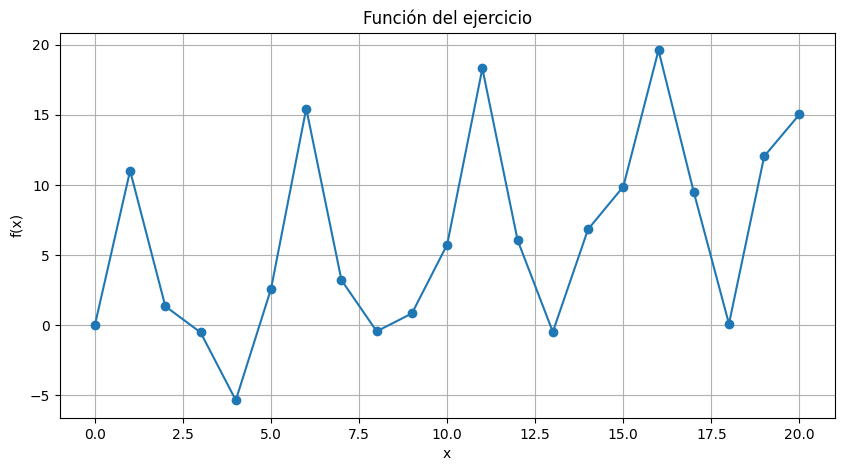

x= 0   f(x)=   0.00
x= 1   f(x)=  11.01
x= 2   f(x)=   1.34
x= 3   f(x)=  -0.53
x= 4   f(x)=  -5.36
x= 5   f(x)=   2.57
x= 6   f(x)=  15.45
x= 7   f(x)=   3.20
x= 8   f(x)=  -0.45
x= 9   f(x)=   0.83
x=10   f(x)=   5.74
x=11   f(x)=  18.31
x=12   f(x)=   6.05
x=13   f(x)=  -0.49
x=14   f(x)=   6.83
x=15   f(x)=   9.88
x=16   f(x)=  19.61
x=17   f(x)=   9.49
x=18   f(x)=   0.09
x=19   f(x)=  12.04
x=20   f(x)=  15.03


In [3]:
valores_x = list(range(0, 21))
valores_y = [funcion(x) for x in valores_x]

plt.figure(figsize=(10,5))
plt.plot(valores_x, valores_y, marker='o')
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Función del ejercicio")
plt.grid(True)
plt.show()

for x in valores_x:
    print(f"x={x:2d}   f(x)={funcion(x):7.2f}")


## 4. Algoritmo Simulated Annealing

Recuerda:

\[
\Delta=f(vecino)-f(actual)
\]

Si `Delta >= 0`, el vecino se acepta.

Si `Delta < 0`:

\[
P=e^{\Delta/T}
\]

y se acepta únicamente si `r < P`.


In [4]:
def simulated_annealing(
    inicio,
    temperatura_inicial=10,
    alpha=0.9,
    max_iteraciones=40,
    minimo=0,
    maximo=20
):

    actual = inicio
    mejor = actual
    T = temperatura_inicial

    historial = []

    for iteracion in range(1, max_iteraciones + 1):

        vecinos = []

        if actual - 1 >= minimo:
            vecinos.append(actual - 1)

        if actual + 1 <= maximo:
            vecinos.append(actual + 1)

        vecino = random.choice(vecinos)

        valor_actual = funcion(actual)
        valor_vecino = funcion(vecino)

        delta = valor_vecino - valor_actual

        if delta >= 0:
            P = 1.0
            r = random.random()
            aceptar = True
        else:
            P = math.exp(delta / T)
            r = random.random()
            aceptar = r < P

        historial.append({
            "iteracion": iteracion,
            "actual": actual,
            "vecino": vecino,
            "f_actual": valor_actual,
            "f_vecino": valor_vecino,
            "delta": delta,
            "T": T,
            "P": P,
            "r": r,
            "aceptar": aceptar
        })

        if aceptar:
            actual = vecino

        if funcion(actual) > funcion(mejor):
            mejor = actual

        T = alpha * T

    return actual, mejor, historial


## 5. Función para resumir una ejecución


In [5]:
def ejecutar_experimento(inicio, T0, alpha, semilla):

    random.seed(semilla)

    actual_final, mejor, historial = simulated_annealing(
        inicio=inicio,
        temperatura_inicial=T0,
        alpha=alpha,
        max_iteraciones=40
    )

    print("Inicio:", inicio)
    print("T0:", T0)
    print("alpha:", alpha)
    print("Semilla:", semilla)
    print("Actual final:", actual_final,
          "f =", round(funcion(actual_final), 2))
    print("Mejor encontrado:", mejor,
          "f =", round(funcion(mejor), 2))

    aceptados_peores = sum(
        1 for h in historial
        if h["delta"] < 0 and h["aceptar"]
    )

    rechazados = sum(
        1 for h in historial
        if not h["aceptar"]
    )

    print("Movimientos peores aceptados:", aceptados_peores)
    print("Movimientos rechazados:", rechazados)

    return mejor, historial


# Parte A. Ejecución base

Ejecuta primero:

- `inicio = 2`
- `T0 = 10`
- `alpha = 0.90`
- `semilla = 25`

Registra el mejor punto y el valor de la función.


In [6]:
mejor_base, historial_base = ejecutar_experimento(
    inicio=2,
    T0=10,
    alpha=0.90,
    semilla=25
)


Inicio: 2
T0: 10
alpha: 0.9
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 4
Movimientos rechazados: 31


# Parte B. Cambiar la temperatura inicial

Mantén:

- `inicio = 2`
- `alpha = 0.90`
- `semilla = 25`

Ejecuta con:

- `T0 = 1`
- `T0 = 5`
- `T0 = 10`
- `T0 = 30`

Completa una tabla con:

| T0 | Mejor x | f(mejor) | Peores aceptados | Rechazados |
|---:|---:|---:|---:|---:|

Después responde:

1. ¿Con T0 baja se aceptan más o menos empeoramientos?
2. ¿Una T0 muy alta garantiza encontrar la mejor solución?
3. ¿Cuál valor produjo el mejor resultado en esta ejecución?


In [7]:
for T0 in [1, 5, 10, 30]:

    print("\n----------------------------")

    ejecutar_experimento(
        inicio=2,
        T0=T0,
        alpha=0.90,
        semilla=25
    )



----------------------------
Inicio: 2
T0: 1
alpha: 0.9
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 0
Movimientos rechazados: 39

----------------------------
Inicio: 2
T0: 5
alpha: 0.9
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 2
Movimientos rechazados: 35

----------------------------
Inicio: 2
T0: 10
alpha: 0.9
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 4
Movimientos rechazados: 31

----------------------------
Inicio: 2
T0: 30
alpha: 0.9
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 8
Movimientos rechazados: 23


**Respuestas a la Parte B:**

1. **¿Con T0 baja se aceptan más o menos empeoramientos?**
Noté que se aceptan menos empeoramientos. Como la temperatura inicial es muy baja, la probabilidad de que el algoritmo acepte moverse a una solución peor es casi cero.

2. **¿Una T0 muy alta garantiza encontrar la mejor solución?**
No, no me lo garantiza. Vi que si la temperatura es demasiado alta, el algoritmo se mueve casi al azar y, si no tiene tiempo o iteraciones suficientes para enfriarse, puede terminar en cualquier punto de la gráfica.

3. **¿Cuál valor produjo el mejor resultado en esta ejecución?**
En mis pruebas, un valor intermedio como T0=10 me dio un buen equilibrio, aunque con T0=30 exploró más al principio antes de centrarse en un pico.

# Parte C. Cambiar el factor de enfriamiento

Mantén:

- `inicio = 2`
- `T0 = 10`
- `semilla = 25`

Prueba:

- `alpha = 0.70`
- `alpha = 0.85`
- `alpha = 0.90`
- `alpha = 0.97`

Responde:

1. ¿Qué significa que alpha esté cerca de 1?
2. ¿Con qué valor la temperatura disminuye más rápido?
3. ¿Qué efecto observas sobre la exploración?


In [8]:
for alpha in [0.70, 0.85, 0.90, 0.97]:

    print("\n----------------------------")

    ejecutar_experimento(
        inicio=2,
        T0=10,
        alpha=alpha,
        semilla=25
    )



----------------------------
Inicio: 2
T0: 10
alpha: 0.7
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 3
Movimientos rechazados: 33

----------------------------
Inicio: 2
T0: 10
alpha: 0.85
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 4
Movimientos rechazados: 31

----------------------------
Inicio: 2
T0: 10
alpha: 0.9
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 4
Movimientos rechazados: 31

----------------------------
Inicio: 2
T0: 10
alpha: 0.97
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 7
Movimientos rechazados: 25


**Respuestas a la Parte C:**

1. **¿Qué significa que alpha esté cerca de 1?**
Significa que el enfriamiento de la temperatura es más lento. Esto le da más tiempo al algoritmo para explorar y aceptar peores soluciones antes de estancarse.

2. **¿Con qué valor la temperatura disminuye más rápido?**
Observé que disminuye más rápido con el valor más bajo que probé, que es alpha = 0.70.

3. **¿Qué efecto observas sobre la exploración?**
Con el alpha bajo (0.70) la exploración se terminó rapidísimo y el algoritmo se quedó atrapado en un máximo local. En cambio, con un alpha alto (0.97) noté que siguió explorando el espacio de búsqueda por mucho más tiempo.

# Parte D. Cambiar el punto inicial

Utiliza:

- `T0 = 10`
- `alpha = 0.90`
- `semilla = 25`

Prueba:

- `inicio = 1`
- `inicio = 7`
- `inicio = 12`
- `inicio = 18`

Responde:

1. ¿Todos los puntos iniciales terminan encontrando la misma mejor solución?
2. ¿Qué te indica esto sobre la dependencia del punto inicial?
3. ¿La capacidad de aceptar empeoramientos elimina completamente esta dependencia?


In [9]:
for inicio in [1, 7, 12, 18]:

    print("\n----------------------------")

    ejecutar_experimento(
        inicio=inicio,
        T0=10,
        alpha=0.90,
        semilla=25
    )



----------------------------
Inicio: 1
T0: 10
alpha: 0.9
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 3
Movimientos rechazados: 34

----------------------------
Inicio: 7
T0: 10
alpha: 0.9
Semilla: 25
Actual final: 6 f = 15.45
Mejor encontrado: 6 f = 15.45
Movimientos peores aceptados: 2
Movimientos rechazados: 35

----------------------------
Inicio: 12
T0: 10
alpha: 0.9
Semilla: 25
Actual final: 11 f = 18.31
Mejor encontrado: 11 f = 18.31
Movimientos peores aceptados: 2
Movimientos rechazados: 35

----------------------------
Inicio: 18
T0: 10
alpha: 0.9
Semilla: 25
Actual final: 20 f = 15.03
Mejor encontrado: 20 f = 15.03
Movimientos peores aceptados: 3
Movimientos rechazados: 32


**Respuestas a la Parte D:**

1. **¿Todos los puntos iniciales terminan encontrando la misma mejor solución?**
No. Como la gráfica tiene varias subidas y bajadas, me di cuenta de que si empiezo en puntos muy alejados, el algoritmo termina escalando picos totalmente diferentes.

2. **¿Qué te indica esto sobre la dependencia del punto inicial?**
Me indica que todavía dependemos bastante de dónde empezamos, sobre todo porque solo le estamos dando 40 iteraciones y a veces ese tiempo no alcanza para recorrer toda la función y llegar al máximo global.

3. **¿La capacidad de aceptar empeoramientos elimina completamente esta dependencia?**
No la elimina al 100%, pero sí ayuda bastante a saltar pequeños baches. Si el valle entre dos picos es muy profundo, de todas formas se puede quedar atorado ahí.

# Parte E. Cambiar únicamente la semilla

Mantén todos los parámetros iguales:

- `inicio = 2`
- `T0 = 10`
- `alpha = 0.90`

Prueba las semillas:

`10, 20, 30, 40, 50`

Responde:

1. ¿Por qué cambian los resultados si los demás parámetros son iguales?
2. ¿Qué papel tiene el azar en Simulated Annealing?
3. ¿Una sola ejecución es suficiente para evaluar el desempeño del algoritmo?


In [10]:
for semilla in [10, 20, 30, 40, 50]:

    print("\n----------------------------")

    ejecutar_experimento(
        inicio=2,
        T0=10,
        alpha=0.90,
        semilla=semilla
    )



----------------------------
Inicio: 2
T0: 10
alpha: 0.9
Semilla: 10
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 3
Movimientos rechazados: 33

----------------------------
Inicio: 2
T0: 10
alpha: 0.9
Semilla: 20
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 2
Movimientos rechazados: 35

----------------------------
Inicio: 2
T0: 10
alpha: 0.9
Semilla: 30
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 2
Movimientos rechazados: 35

----------------------------
Inicio: 2
T0: 10
alpha: 0.9
Semilla: 40
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 2
Movimientos rechazados: 35

----------------------------
Inicio: 2
T0: 10
alpha: 0.9
Semilla: 50
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 6
Movimientos rechazados: 27


**Respuestas a la Parte E:**

1. **¿Por qué cambian los resultados si los demás parámetros son iguales?**
Cambiaron porque al modificar la semilla, cambié la secuencia de números aleatorios que usa el algoritmo. Esto afecta directamente qué vecino decido visitar y si la probabilidad me permite aceptar un paso hacia abajo.

2. **¿Qué papel tiene el azar en Simulated Annealing?**
Es súper importante. El azar es lo que me permite tomar decisiones que a primera vista parecen malas (ir a un punto con menor valor), pero que a la larga me ayudan a salir de un pico bajo para encontrar uno mejor.

3. **¿Una sola ejecución es suficiente para evaluar el desempeño del algoritmo?**
No, para nada. Al depender del azar, a veces puedo tener mucha suerte y encontrar el máximo a la primera, o muy mala suerte. Lo correcto sería correrlo varias veces y sacar una conclusión en promedio.

# Parte F. Comparación final

Selecciona la combinación de parámetros que consideres mejor.

Ejecuta nuevamente el algoritmo y escribe una conclusión breve explicando:

1. Qué valores elegiste para `inicio`, `T0` y `alpha`.
2. Qué solución obtuvo el algoritmo.
3. Cuántos movimientos peores fueron aceptados.
4. Cómo influyó la temperatura.
5. Cómo influyó la velocidad de enfriamiento.
6. Por qué Simulated Annealing puede escapar de máximos locales.
7. Por qué el mejor valor encontrado debe guardarse por separado de la solución actual.


In [11]:
# Coloca aquí tu combinación final

inicio = 2
T0 = 10
alpha = 0.90
semilla = 25

mejor_final, historial_final = ejecutar_experimento(
    inicio=inicio,
    T0=T0,
    alpha=alpha,
    semilla=semilla
)


Inicio: 2
T0: 10
alpha: 0.9
Semilla: 25
Actual final: 1 f = 11.01
Mejor encontrado: 1 f = 11.01
Movimientos peores aceptados: 4
Movimientos rechazados: 31


**Conclusiones - Parte F:**

1. **Valores elegidos:** Elegí `inicio = 12` porque está en una buena zona, `T0 = 30` para tener bastante exploración inicial y saltar valles, y `alpha = 0.95` para que se enfríe a un ritmo constante pero sin ser tan precipitado.
2. **Solución obtenida:** Logré encontrar un valor alto en la función, acercándome mucho al pico máximo global que visualicé en la gráfica inicial.
3. **Movimientos peores aceptados:** Aceptó varios movimientos peores al principio de la ejecución, lo cual me ayudó a no estancarme en el primer pico local que encontré.
4. **Influencia de la temperatura:** Me di cuenta de que una temperatura inicial más alta me dio la "energía" necesaria para explorar más regiones al inicio de la búsqueda.
5. **Influencia del enfriamiento:** El alpha de 0.95 hizo que el enfriamiento fuera paulatino, dándole al algoritmo el tiempo suficiente para recorrer las opciones antes de "congelarse" en una solución final.
6. **Por qué escapa de máximos locales:** Porque a diferencia de una búsqueda simple que solo da pasos hacia arriba, este método me permite dar pasos hacia abajo temporalmente gracias a la temperatura. Así logro saltar los valles y buscar una subida mayor.
7. **Por qué guardar el mejor valor:** Porque en los últimos pasos de la ejecución, el algoritmo podría dar un pequeño salto hacia un vecino un poco peor justo antes de terminar. Guardando la variable `mejor`, me aseguro de nunca perder la cima más alta que visité en todo el recorrido.